SENTIMENT ANALYSIS USING BERT

Device: cuda
GPU: Tesla T4

Loading IMDb dataset...
Training samples: 5000
Testing samples: 1000

Tokenizing data...
Tokenization completed.

Loading BERT model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



TRAINING BERT
Epoch 1/2 - Loss: 0.4196
Epoch 2/2 - Loss: 0.2193

Training completed.

EVALUATING MODEL

Accuracy : 0.864
Precision: 0.8621
Recall   : 0.8586
F1 Score : 0.8604

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87       512
    Positive       0.86      0.86      0.86       488

    accuracy                           0.86      1000
   macro avg       0.86      0.86      0.86      1000
weighted avg       0.86      0.86      0.86      1000



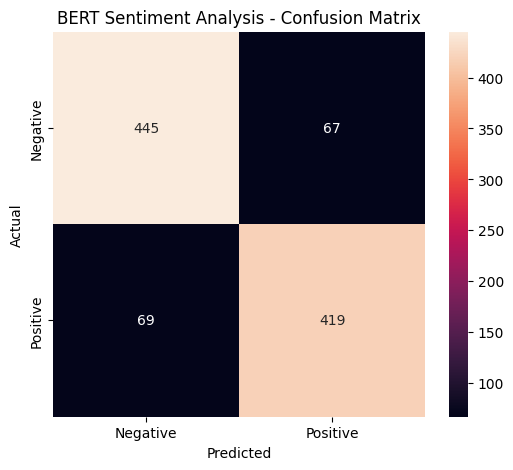


CUSTOM SENTIMENT PREDICTIONS

Text: This movie was absolutely fantastic and I really enjoyed it.
Sentiment: Positive

Text: The movie was boring and a complete waste of time.
Sentiment: Negative

Text: The acting was excellent and the story was amazing.
Sentiment: Positive

Text: I hated this movie. It was terrible.
Sentiment: Negative

PROGRAM COMPLETED SUCCESSFULLY


In [6]:
!pip install -q -U transformers datasets accelerate scikit-learn seaborn matplotlib

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import DataLoader
from torch.optim import AdamW
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

print("=" * 60)
print("SENTIMENT ANALYSIS USING BERT")
print("=" * 60)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nLoading IMDb dataset...")

dataset = load_dataset("stanfordnlp/imdb")

train_dataset = dataset["train"].shuffle(seed=42).select(range(5000))
test_dataset = dataset["test"].shuffle(seed=42).select(range(1000))

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

print("\nTokenizing data...")

train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

train_dataset = train_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])

train_dataset.set_format("torch")
test_dataset.set_format("torch")

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Tokenization completed.")

print("\nLoading BERT model...")

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

model.to(device)

optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

epochs = 2

print("\n" + "=" * 60)
print("TRAINING BERT")
print("=" * 60)

model.train()

for epoch in range(epochs):

    total_loss = 0

    for batch in train_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["label"]
        )

        loss = outputs.loss

        total_loss += loss.item()

        loss.backward()

        optimizer.step()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Loss: {average_loss:.4f}"
    )

print("\nTraining completed.")

print("\n" + "=" * 60)
print("EVALUATING MODEL")
print("=" * 60)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average="binary",
    zero_division=0
)

print("\nAccuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BERT Sentiment Analysis - Confusion Matrix")

plt.show()

def predict_sentiment(text):

    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(
            **inputs
        )

    prediction = torch.argmax(
        outputs.logits,
        dim=1
    ).item()

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

print("\n" + "=" * 60)
print("CUSTOM SENTIMENT PREDICTIONS")
print("=" * 60)

sentences = [
    "This movie was absolutely fantastic and I really enjoyed it.",
    "The movie was boring and a complete waste of time.",
    "The acting was excellent and the story was amazing.",
    "I hated this movie. It was terrible."
]

for sentence in sentences:

    print("\nText:", sentence)
    print("Sentiment:", predict_sentiment(sentence))

print("\n" + "=" * 60)
print("PROGRAM COMPLETED SUCCESSFULLY")
print("=" * 60)